<div style="background:linear-gradient(135deg,#0B2545 0%,#13A89E 100%);padding:26px 30px;border-radius:12px;color:#fff"><h1 style="margin:0;color:#fff">🚢 Titanic Survival — Executive EDA</h1><p style="margin:8px 0 0 0;font-size:15px;opacity:.92">End-to-end Exploratory Data Analysis &nbsp;|&nbsp; Cleaning → Grouped Statistics → Visual Analytics → Executive Report</p></div>

### About this notebook

This notebook follows a step-by-step analytics workflow and explains the **rationale behind every decision**, so it can be
presented to business stakeholders as well as reviewed by analysts. It is built on the Kaggle Titanic dataset
(`train.csv` with labels, `test.csv` without labels).

## Workflow stages

| # | Stage | Question it answers |
|:-:|:--|:--|
| 1 | **Acquire data** | What files do we have and are they loaded correctly? |
| 2 | **Analyze by describing data** | What is the structure, type and quality of every feature? |
| 3 | **Clean & preprocess** | How do we fix missing values and data types, and why? |
| 4 | **Descriptive & grouped statistics** | Who survived? Exact rates by gender, class, age and family |
| 5 | **Visualize** | What do the patterns look like? (Navy / Teal theme) |
| 6 | **Validate statistically** *(bonus)* | Are the differences real or noise? Which drivers matter most? |
| 7 | **Executive summary** | What should leadership know and do? |



<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">1. &nbsp;Setup</h2><span style="color:#cfe9e7;font-size:13px">Libraries, theme and helper functions</span></div>

In [34]:
# data analysis and wrangling
import os, warnings
import numpy as np
import pandas as pd

# visualization
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, HTML

# statistics
from scipy.stats import chi2_contingency

# machine learning (used only for a driver-ranking sanity check)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [35]:
# ---------- Design system: Navy / Teal ----------
NAVY, BLUE, TEAL, GREY, AMBER = "#0B2545", "#1F6F8B", "#13A89E", "#8D99AE", "#E09F3E"
TEAL_CMAP = LinearSegmentedColormap.from_list("teal_scale", ["#F4FBFA", "#7FD1CA", TEAL])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans",
    "axes.spines.top": False, "axes.spines.right": False,      # hidden top / right spines
    "axes.edgecolor": "#444", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.labelsize": 11, "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True,
})
sns.set_palette([NAVY, TEAL, BLUE, GREY])
os.makedirs("figures", exist_ok=True)

def save_fig(name):
    """Save a high-DPI copy for the presentation, then display it."""
    plt.savefig(f"figures/{name}.png", bbox_inches="tight", dpi=300)
    plt.show()

def kpi_cards(cards):
    """Render executive KPI cards: [(label, value, sub-label), ...]"""
    html = '<div style="display:flex;gap:12px;flex-wrap:wrap;margin:6px 0">'
    for label, value, sub in cards:
        html += (f'<div style="flex:1;min-width:150px;background:{NAVY};color:#fff;border-radius:10px;'
                 f'padding:14px 16px;border-top:4px solid {TEAL}">'
                 f'<div style="font-size:12px;opacity:.8">{label}</div>'
                 f'<div style="font-size:26px;font-weight:700">{value}</div>'
                 f'<div style="font-size:11px;opacity:.7">{sub}</div></div>')
    display(HTML(html + "</div>"))

def style_table(t, pct_cols=("Survival %",)):
    """Presentation-ready styled table with a teal heat scale on rate columns."""
    fmt = {c: "{:.1f}%" for c in pct_cols if c in t.columns}
    for c in ("Passengers", "Survivors"):
        if c in t.columns: fmt[c] = "{:,.0f}"
    sty = t.style.format(fmt)
    cols = [c for c in pct_cols if c in t.columns]
    if cols: sty = sty.background_gradient(subset=cols, cmap=TEAL_CMAP, vmin=0, vmax=100)
    return sty.set_table_styles([
        {"selector": "th.col_heading", "props": [("background-color", NAVY), ("color", "white")]},
        {"selector": "th", "props": [("text-align", "center")]}])

<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">2. &nbsp;Acquire data</h2><span style="color:#cfe9e7;font-size:13px">Load the original Kaggle files directly</span></div>

We load `train.csv` (891 passengers, includes the `Survived` label) and `test.csv` (418 passengers, **no label**).
The loader looks in the usual places (current folder, Colab `/content`, Google Drive, Kaggle `../input`) and, if the file is
not found, opens the Colab upload dialog.

> **Note:** all survival statistics use `train.csv` because only that file contains the answer. `test.csv` is used only for a data-quality comparison.

In [36]:
SEARCH_DIRS = [".", "/content", "/content/drive/MyDrive", "/content/drive/MyDrive/titanic",
               "../input", "/kaggle/input/titanic", "/kaggle/input"]

def find_file(name):
    for d in SEARCH_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    return None

# Ask for the files only if train.csv is not already available
if find_file("train.csv") is None:
    try:
        from google.colab import files
        print("📂 Please select train.csv (and test.csv if you have it)...")
        files.upload()                       # files land in the current folder (/content)
    except ImportError:
        raise FileNotFoundError("train.csv not found. Place it next to this notebook.")

train_path, test_path = find_file("train.csv"), find_file("test.csv")
assert train_path, "train.csv still not found - please upload it and re-run this cell."

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path) if test_path else None

print(f"✅ train.csv loaded from: {train_path}  ->  {train_df.shape[0]:,} rows x {train_df.shape[1]} columns")
print(f"{'✅' if test_df is not None else 'ℹ️'} test.csv: " +
      (f"{test_df.shape[0]:,} rows x {test_df.shape[1]} columns" if test_df is not None else "not provided (optional)"))

✅ train.csv loaded from: ./train.csv  ->  891 rows x 12 columns
✅ test.csv: 418 rows x 11 columns


<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">3. &nbsp;Analyze by describing data</h2><span style="color:#cfe9e7;font-size:13px">Structure, data types, distributions and quality</span></div>

**Which features are available in the dataset?**

These are described on the [Kaggle data page](https://www.kaggle.com/c/titanic/data).

In [37]:
print(train_df.columns.values)

['PassengerId' 'Survived' 'Pclass' 'Name' 'Sex' 'Age' 'SibSp' 'Parch'
 'Ticket' 'Fare' 'Cabin' 'Embarked']


**Which features are categorical, numerical or mixed?**

- **Categorical:** `Survived`, `Sex`, `Embarked`. **Ordinal:** `Pclass`.
- **Numerical, continuous:** `Age`, `Fare`. **Numerical, discrete:** `SibSp`, `Parch`.
- **Mixed / alphanumeric:** `Ticket` (digits + letters), `Cabin` (deck letter + number). `Name` is free text containing titles.

In [38]:
# preview the data
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


In [39]:
train_df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.00,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.00,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.00,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.00,0,0,370376,7.75,NaN,Q


**Which features contain blank, null or empty values, and what are the data types?**

This tells us what must be corrected before any analysis.

In [40]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [41]:
# Missing-value audit (train vs. test)
audit = pd.DataFrame({
    "train_missing": train_df.isna().sum(),
    "train_%": (train_df.isna().mean() * 100).round(1),
})
if test_df is not None:
    audit["test_missing"] = test_df.isna().sum()
    audit["test_%"] = (test_df.isna().mean() * 100).round(1)
audit = audit[(audit.train_missing > 0) | (audit.get("test_missing", 0) > 0)].sort_values("train_missing", ascending=False)

display(audit.style.format("{:,.1f}").background_gradient(subset=["train_%"], cmap="Blues")
        .set_table_styles([{"selector": "th.col_heading", "props": [("background-color", NAVY), ("color", "white")]}]))

print(f"Duplicate rows: {train_df.duplicated().sum()}  |  Duplicate PassengerIds: {train_df.PassengerId.duplicated().sum()}")

,train_missing,train_%,test_missing,test_%
Cabin,687.0,77.1,327.0,78.2
Age,177.0,19.9,86.0,20.6
Embarked,2.0,0.2,0.0,0.0
Fare,0.0,0.0,1.0,0.2


Duplicate rows: 0  |  Duplicate PassengerIds: 0


In [42]:
n_missing_cells = int(train_df.isna().sum().sum())
kpi_cards([
    ("Passengers (train)", f"{len(train_df):,}", "labelled records"),
    ("Features", f"{train_df.shape[1]}", "raw columns"),
    ("Overall survival", f"{train_df.Survived.mean():.1%}", f"{train_df.Survived.sum()} of {len(train_df)} survived"),
    ("Worst missing column", "Cabin", f"{train_df.Cabin.isna().mean():.1%} missing"),
    ("Duplicates", f"{train_df.duplicated().sum()}", "rows / IDs"),
])

<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observations</b><ul style="margin:6px 0 2px 0"><li><b>Cabin</b> (77.1%) &gt; <b>Age</b> (19.9%) &gt; <b>Embarked</b> (0.2%, two rows) contain nulls in the training data. In the test data Cabin, Age and one <b>Fare</b> are incomplete.</li><li>There are <b>no duplicate</b> passengers or IDs, so no de-duplication is needed.</li><li><b>Seven</b> columns are numeric (integers or floats) and <b>five</b> are text (<code>object</code>).</li></ul></div>

**What is the distribution of numerical features?**

In [43]:
train_df.describe(percentiles=[.1, .25, .5, .75, .9, .99])

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
10%,90.00,0.00,1.00,14.00,0.00,0.00,7.55
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
90%,802.00,1.00,3.00,50.00,1.00,2.00,77.96
99%,882.10,1.00,3.00,65.87,5.00,4.00,249.01


**What is the distribution of categorical features?**

In [44]:
train_df.describe(include=['O'])

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observations</b><ul style="margin:6px 0 2px 0"><li>The sample is <b>891 passengers</b>, about 40% of the 2,224 people aboard. About <b>38%</b> survived (the real-world figure was about 32%).</li><li>Most passengers (&gt;75%) travelled <b>without parents or children</b>; fares are heavily right-skewed, with a few passengers paying up to <b>$512</b>.</li><li>Names are unique (count = unique = 891). <b>65% are male</b> (577 of 891).</li><li><b>Embarked</b> has three ports; Southampton (S) dominates with 644 passengers.</li><li><b>Ticket</b> has 681 unique values out of 891 (shared tickets = group travel). <b>Cabin</b> has 147 unique values among the 204 known entries.</li></ul></div>

<div style="border-left:6px solid #0B2545;background:#0B25451F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>✅ Assumptions to carry into the analysis</b><ul style="margin:6px 0 2px 0"><li><b>Completing:</b> Age is strongly related to class and gender, so it must be completed with a group-aware method. Embarked needs a simple fill.</li><li><b>Correcting:</b> Cabin is too sparse to impute, so we convert it into a known/unknown signal. Ticket is treated as non-informative.</li><li><b>Creating:</b> derive <i>Family_Size</i>, <i>Age brackets</i> and a <i>Cabin_Known</i> flag.</li><li><b>Classifying:</b> expect women, children and first-class passengers to have higher survival.</li></ul></div>

<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">4. &nbsp;Data cleaning &amp; preprocessing</h2><span style="color:#cfe9e7;font-size:13px">Impute, convert types, engineer features, validate</span></div>

We now execute the decisions above. All work is performed on a copy (`df`) so the raw data (`train_df`) stays untouched for audit purposes.

### 4.1 Is the missingness random?

Before imputing `Age`, check whether its missing rate differs by segment. If it does, a single global median would bias the result.

In [45]:
df = train_df.copy()

miss_by_class = (df.assign(Age_Missing=df["Age"].isna()).groupby("Pclass")["Age_Missing"].mean() * 100).round(1)
miss_by_class.to_frame("Age missing %").T

Pclass,1,2,3
Age missing %,13.90,6.00,27.70


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observation</b><ul style="margin:6px 0 2px 0"><li>Age is missing for <b>27.7%</b> of third-class passengers but only <b>13.9%</b> (1st) and <b>6.0%</b> (2nd). The data is <b>not missing completely at random</b>.</li></ul></div>

<div style="border-left:6px solid #0B2545;background:#0B25451F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>✅ Decision</b><ul style="margin:6px 0 2px 0"><li>Impute Age with the <b>median of each Pclass &times; Sex group</b> instead of a global value, and keep an <code>Age_Was_Missing</code> flag so the imputation stays traceable.</li></ul></div>

### 4.2 Completing a numerical feature: `Age`

The median is preferred to the mean because it is robust to outliers (a handful of passengers are 70+). Let's inspect the medians we will use.

In [46]:
age_medians = df.groupby(["Pclass", "Sex"])["Age"].median().unstack()
display(age_medians.style.format("{:.1f}").background_gradient(cmap=TEAL_CMAP)
        .set_caption("Median age by Pclass x Sex (used for imputation)"))

Sex,female,male
Pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


In [47]:
age_before = df["Age"].copy()

df["Age_Was_Missing"] = df["Age"].isna().astype(int)
df["Age"] = df["Age"].fillna(df.groupby(["Pclass", "Sex"])["Age"].transform("median"))

# Sanity check: imputation should not distort the distribution
check = pd.DataFrame({"Before (non-null only)": age_before.describe(), "After imputation": df["Age"].describe()}).loc[["count", "mean", "std", "50%"]]
check

,Before (non-null only),After imputation
count,714.00,891.00
mean,29.70,29.11
std,14.53,13.30
50%,28.00,26.00


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Validation</b><ul style="margin:6px 0 2px 0"><li>All 177 gaps are filled and the central value stays close (mean 29.7 &rarr; 29.1, median 28 &rarr; 26). The spread narrows slightly (std 14.5 &rarr; 13.3), the usual side effect of median imputation, which is acceptable here and is why we also keep the <code>Age_Was_Missing</code> flag.</li></ul></div>

### 4.3 Completing a categorical feature: `Embarked`

Only **two** values are missing (0.2%). We fill them with the **mode** (the most frequent port), the lowest-risk choice for such a tiny gap.

In [48]:
freq_port = df["Embarked"].mode()[0]
print("Most frequent port:", freq_port)
print("Rows to fill:\n", df.loc[df.Embarked.isna(), ["PassengerId", "Pclass", "Fare", "Cabin"]])

df["Embarked"] = df["Embarked"].fillna(freq_port)

Most frequent port: S
Rows to fill:
      PassengerId  Pclass  Fare Cabin
61            62       1 80.00   B28
829          830       1 80.00   B28


### 4.4 Handling `Cabin` gracefully

77% of cabins are missing, so imputing would be fabrication. Instead we turn the *absence* into information:

- `Cabin_Known` &rarr; 1 if a cabin was recorded, else 0
- `Deck` &rarr; the first letter of the cabin (A&ndash;G, T), or `Unknown`

In [49]:
df["Cabin_Known"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0].fillna("Unknown")

df.groupby("Cabin_Known")["Survived"].agg(Passengers="count", Survival_Rate="mean").assign(Survival_Rate=lambda t: (t.Survival_Rate * 100).round(1))

,Passengers,Survival_Rate
Cabin_Known,,
0,687,30.00
1,204,66.70


<div style="border-left:6px solid #1F6F8B;background:#1F6F8B1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>💡 Why this matters</b><ul style="margin:6px 0 2px 0"><li>Passengers with a recorded cabin survived at <b>66.7%</b> vs <b>30.0%</b> without. Cabin records skew heavily toward first class (<b>86%</b> of known cabins vs <b>6%</b> of unknown), so this flag is a <b>proxy for status and record quality</b>, not a causal effect of the cabin itself.</li></ul></div>

### 4.5 Converting data types

- `Sex`, `Embarked`, `Deck` &rarr; **category** (memory-efficient, explicit domain)
- `Pclass` &rarr; **ordered category** (1st &gt; 2nd &gt; 3rd)

In [50]:
for col in ["Sex", "Embarked", "Deck"]:
    df[col] = df[col].astype("category")
df["Pclass"] = pd.Categorical(df["Pclass"], categories=[1, 2, 3], ordered=True)

df[["Sex", "Embarked", "Deck", "Pclass"]].dtypes.to_frame("dtype").T

,Sex,Embarked,Deck,Pclass
dtype,category,category,category,category


### 4.6 Creating new features

| Feature | Definition | Purpose |
|:--|:--|:--|
| `Family_Size` | `SibSp + Parch + 1` | Group travel context |
| `Family_Group` | Alone (1), Small (2-4), Large (5+) | Captures the non-linear family effect |
| `Age_Group` | Child (0-12), Youth (13-25), Adult (26-60), Senior (61+) | Business-friendly age brackets |
| `Title` | Extracted from `Name` (Mr, Mrs, Miss, Master, ...) | Social-status signal |

In [51]:
df["Family_Size"] = df["SibSp"] + df["Parch"] + 1

df["Family_Group"] = pd.cut(df["Family_Size"], bins=[0, 1, 4, 20],
                            labels=["Alone (1)", "Small (2-4)", "Large (5+)"])

df["Age_Group"] = pd.cut(df["Age"], bins=[0, 12, 25, 60, 120],
                         labels=["Child (0-12)", "Youth (13-25)", "Adult (26-60)", "Senior (61+)"])

# Title: group rare titles together (same idea as the classic Titanic workflow)
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
df["Title"] = df["Title"].replace(["Lady", "Countess", "Capt", "Col", "Don", "Dr", "Major", "Rev", "Sir", "Jonkheer", "Dona"], "Rare")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

df[["Name", "Title", "Age", "Age_Group", "Family_Size", "Family_Group", "Cabin_Known"]].head(8)

,Name,Title,Age,Age_Group,Family_Size,Family_Group,Cabin_Known
0,"Braund, Mr. Owen Harris",Mr,22.00,Youth (13-25),2,Small (2-4),0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.00,Adult (26-60),2,Small (2-4),1
2,"Heikkinen, Miss. Laina",Miss,26.00,Adult (26-60),1,Alone (1),0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.00,Adult (26-60),2,Small (2-4),1
4,"Allen, Mr. William Henry",Mr,35.00,Adult (26-60),1,Alone (1),0
5,"Moran, Mr. James",Mr,25.00,Youth (13-25),1,Alone (1),0
6,"McCarthy, Mr. Timothy J",Mr,54.00,Adult (26-60),1,Alone (1),1
7,"Palsson, Master. Gosta Leonard",Master,2.00,Child (0-12),5,Large (5+),0


### 4.7 Validation: is the cleaned dataset analysis-ready?

In [52]:
remaining = df.drop(columns="Cabin").isna().sum()
assert remaining.sum() == 0, f"Unexpected nulls remain:\n{remaining[remaining > 0]}"
print("✅ Zero missing values outside the raw Cabin column (kept intentionally via Cabin_Known / Deck).")
print(f"✅ Final shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

✅ Zero missing values outside the raw Cabin column (kept intentionally via Cabin_Known / Deck).
✅ Final shape: 891 rows x 19 columns


<div style="border-left:6px solid #0B2545;background:#0B25451F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>✅ Cleaning summary</b><ul style="margin:6px 0 2px 0"><li><b>Age</b> &rarr; group median (Pclass &times; Sex) + <code>Age_Was_Missing</code> flag.</li><li><b>Embarked</b> &rarr; mode (<code>S</code>).</li><li><b>Cabin</b> &rarr; not imputed; converted to <code>Cabin_Known</code> and <code>Deck</code>.</li><li><b>Types</b> &rarr; categoricals set explicitly; <code>Pclass</code> is ordered.</li><li><b>New features</b> &rarr; <code>Family_Size</code>, <code>Family_Group</code>, <code>Age_Group</code>, <code>Title</code>.</li></ul></div>

<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">5. &nbsp;Descriptive &amp; grouped statistics</h2><span style="color:#cfe9e7;font-size:13px">Exact survival rates by segment</span></div>

Pivoting features against `Survived` quickly confirms (or rejects) our assumptions. We define one reusable helper so every table has the same layout.

> **Baseline for comparison:** overall survival is **38.4%**.

In [53]:
def survival_table(by):
    """Passengers, survivors and exact survival rate for any grouping."""
    t = df.groupby(by, observed=True)["Survived"].agg(Passengers="count", Survivors="sum", Rate="mean")
    t["Survival %"] = (t["Rate"] * 100).round(1)
    return t.drop(columns="Rate")

overall = df["Survived"].mean()
print(f"Overall survival rate: {overall:.1%}")

Overall survival rate: 38.4%


### 5.1 By gender

In [54]:
style_table(survival_table('Sex'))

,Passengers,Survivors,Survival %
Sex,,,
female,314,233,74.2%
male,577,109,18.9%


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Key takeaways</b><ul style="margin:6px 0 2px 0"><li>Women survived at <b>74.2%</b>, men at <b>18.9%</b>, a <b>4&times;</b> difference.</li><li>Women were 35% of passengers but <b>68%</b> of survivors (233 of 342).</li></ul></div>

### 5.2 By ticket class

In [55]:
style_table(survival_table('Pclass'))

,Passengers,Survivors,Survival %
Pclass,,,
1,216,136,63.0%
2,184,87,47.3%
3,491,119,24.2%


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Key takeaways</b><ul style="margin:6px 0 2px 0"><li>Survival falls steadily with class: <b>63.0% &rarr; 47.3% &rarr; 24.2%</b>.</li><li>Third class was <b>55%</b> of passengers but only <b>35%</b> of survivors.</li></ul></div>

### 5.3 Gender &times; class (the most revealing cut)

In [56]:
style_table(survival_table(['Sex', 'Pclass']))

In [57]:
# Same data as a compact matrix (rows = class, columns = gender)
matrix = (df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean", observed=True) * 100).round(1)
display(matrix.style.format("{:.1f}%").background_gradient(cmap=TEAL_CMAP, vmin=0, vmax=100)
        .set_table_styles([{"selector": "th.col_heading", "props": [("background-color", NAVY), ("color", "white")]}]))

Sex,female,male
Pclass,,
1,96.8%,36.9%
2,92.1%,15.7%
3,50.0%,13.5%


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Key takeaways</b><ul style="margin:6px 0 2px 0"><li>Range is <b>96.8%</b> (1st-class women) down to <b>13.5%</b> (3rd-class men), an <b>83-point</b> gap.</li><li>Class mattered far more for women (96.8% &rarr; 50.0%) than for men (36.9% &rarr; 13.5%).</li><li>A <b>3rd-class woman (50.0%)</b> had better odds than a <b>1st-class man (36.9%)</b>: gender outranked class.</li></ul></div>

### 5.4 By age bracket

In [58]:
style_table(survival_table('Age_Group'))

,Passengers,Survivors,Survival %
Age_Group,,,
Child (0-12),69,40,58.0%
Youth (13-25),368,118,32.1%
Adult (26-60),432,179,41.4%
Senior (61+),22,5,22.7%


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Key takeaways</b><ul style="margin:6px 0 2px 0"><li><b>Children (0-12) survived at 58.0%</b>, the highest of any age band: consistent with 'women and children first'.</li><li>Youth (13-25) had the lowest rate among large groups (32.1%); seniors were lowest overall (22.7%) but only <b>22 people</b>, so treat it as indicative.</li></ul></div>

### 5.5 By family size

In [59]:
style_table(survival_table('Family_Size'))

,Passengers,Survivors,Survival %
Family_Size,,,
1,537,163,30.4%
2,161,89,55.3%
3,102,59,57.8%
4,29,21,72.4%
5,15,3,20.0%
6,22,3,13.6%
7,12,4,33.3%
8,6,0,0.0%
11,7,0,0.0%


In [60]:
style_table(survival_table('Family_Group'))

,Passengers,Survivors,Survival %
Family_Group,,,
Alone (1),537,163,30.4%
Small (2-4),292,169,57.9%
Large (5+),62,10,16.1%


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Key takeaways</b><ul style="margin:6px 0 2px 0"><li>The effect is <b>non-linear</b>: small families (2-4) survived at <b>57.9%</b>, solo travellers at 30.4%, and large families (5+) at only <b>16.1%</b>.</li><li>Families of 8 and 11 had <b>0%</b> survival (small samples), but the pattern holds across the larger groups too.</li></ul></div>

### 5.6 Bonus cuts: port of embarkation, cabin record and title

In [61]:
style_table(survival_table('Embarked'))

,Passengers,Survivors,Survival %
Embarked,,,
C,168,93,55.4%
Q,77,30,39.0%
S,646,219,33.9%


In [62]:
style_table(survival_table('Title'))

,Passengers,Survivors,Survival %
Title,,,
Master,40,23,57.5%
Miss,185,130,70.3%
Mr,517,81,15.7%
Mrs,126,100,79.4%
Rare,23,8,34.8%


<div style="border-left:6px solid #E09F3E;background:#E09F3E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>⚠️ Interpretation caution</b><ul style="margin:6px 0 2px 0"><li>Cherbourg (C) shows 55.4% survival vs 33.9% for Southampton, but <b>51%</b> of Cherbourg passengers were first class versus only <b>20%</b> at Southampton. Much of the 'port effect' is really a <b>class effect</b>.</li><li>By title, <b>Mrs (79.4%)</b>, <b>Miss (70.3%)</b> and <b>Master (boys, 57.5%)</b> survived far more than <b>Mr (15.7%)</b>, which reinforces the gender and age findings.</li></ul></div>

<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">6. &nbsp;Visualizations</h2><span style="color:#cfe9e7;font-size:13px">Navy / Teal theme &bull; 300 DPI exports saved to <code>figures/</code></span></div>

We start with the three core charts requested, then add supporting visuals. Every chart carries percentage labels, clear axis titles and hidden top/right spines.

### 6.1 Survival rates by gender and class

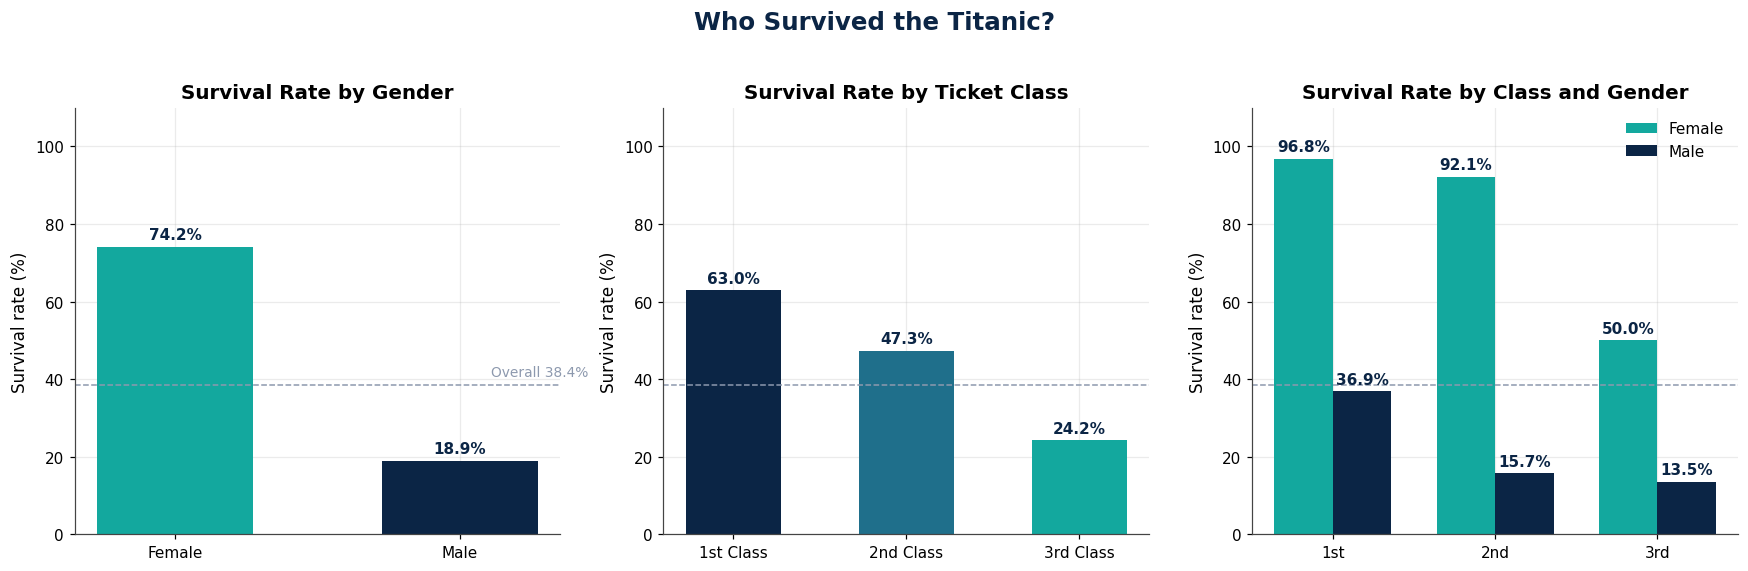

In [63]:
def label_bars(ax, fmt="{:.1f}%"):
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h), ha="center", va="bottom",
                        fontsize=10, fontweight="bold", color=NAVY, xytext=(0, 3), textcoords="offset points")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

g = df.groupby("Sex", observed=True)["Survived"].mean().mul(100)
axes[0].bar(g.index.astype(str).str.title(), g.values, color=[TEAL, NAVY], width=.55)
axes[0].set_title("Survival Rate by Gender")

c = df.groupby("Pclass", observed=True)["Survived"].mean().mul(100)
axes[1].bar(["1st Class", "2nd Class", "3rd Class"], c.values, color=[NAVY, BLUE, TEAL], width=.55)
axes[1].set_title("Survival Rate by Ticket Class")

gc = df.groupby(["Pclass", "Sex"], observed=True)["Survived"].mean().mul(100).unstack()
x, w = np.arange(3), .36
axes[2].bar(x - w/2, gc["female"], w, color=TEAL, label="Female")
axes[2].bar(x + w/2, gc["male"], w, color=NAVY, label="Male")
axes[2].set_xticks(x); axes[2].set_xticklabels(["1st", "2nd", "3rd"])
axes[2].set_title("Survival Rate by Class and Gender"); axes[2].legend(frameon=False)

for ax in axes:
    ax.set_ylim(0, 110); ax.set_ylabel("Survival rate (%)"); label_bars(ax)
    ax.axhline(overall * 100, color=GREY, ls="--", lw=1)
axes[0].text(1.45, overall * 100 + 2.5, f"Overall {overall:.1%}", color=GREY, fontsize=9, ha="right")

fig.suptitle("Who Survived the Titanic?", fontsize=16, fontweight="bold", color=NAVY, y=1.03)
plt.tight_layout()
save_fig("01_survival_bars")

<div style="border-left:6px solid #1F6F8B;background:#1F6F8B1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>💡 Reading the chart</b><ul style="margin:6px 0 2px 0"><li>The dashed line is the <b>38.4%</b> overall average. All three female segments sit above that line (3rd-class women at exactly 50.0%); all three male segments sit below it, with 1st-class men (36.9%) only just under.</li></ul></div>

### 6.2 Correlation matrix heatmap

We include numeric variables plus two encoded flags (`Sex_Female`, `Cabin_Known`). The upper triangle is masked to avoid duplicate information.

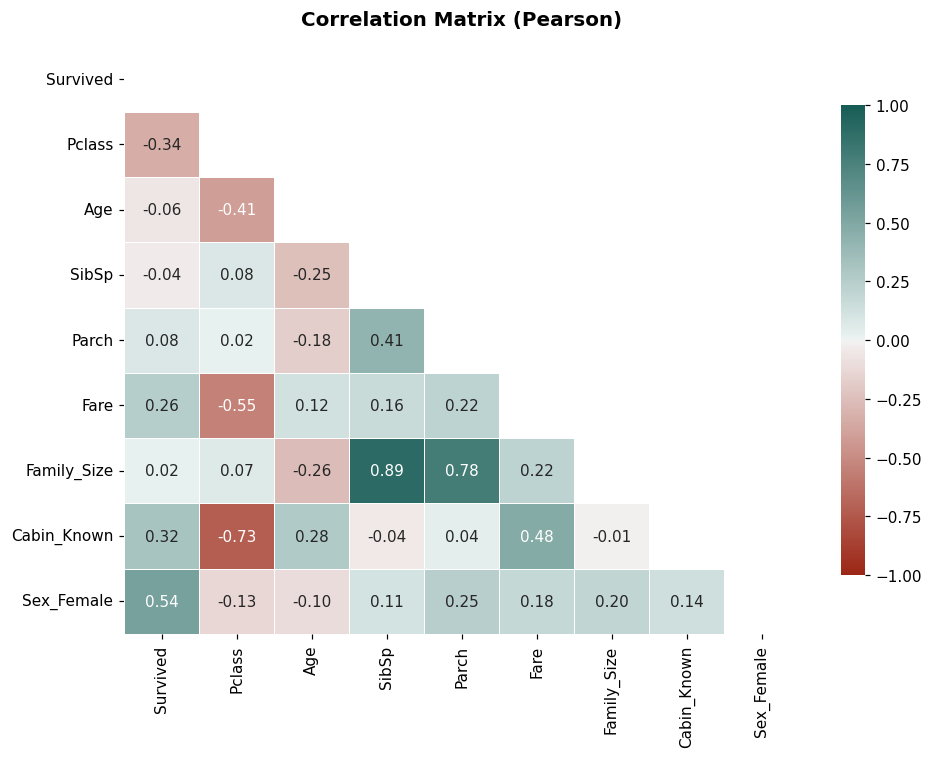

,Sex_Female,Cabin_Known,Fare,Parch,Family_Size,SibSp,Age,Pclass
Correlation with Survived,0.54,0.32,0.26,0.08,0.02,-0.04,-0.06,-0.34


In [64]:
num = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "Family_Size", "Cabin_Known"]].copy()
num["Pclass"] = num["Pclass"].astype(int)
num["Sex_Female"] = (df["Sex"] == "female").astype(int)

corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", linewidths=.5, center=0, vmin=-1, vmax=1,
            cmap=sns.diverging_palette(15, 180, s=90, l=35, as_cmap=True), cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation Matrix (Pearson)", pad=14); ax.grid(False)
plt.tight_layout()
save_fig("02_correlation_heatmap")

corr["Survived"].drop("Survived").sort_values(ascending=False).round(2).to_frame("Correlation with Survived").T

<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observations</b><ul style="margin:6px 0 2px 0"><li><b>Sex_Female (+0.54)</b> is the strongest single correlate of survival, followed by <b>Pclass (&minus;0.34)</b>, <b>Cabin_Known (+0.32)</b> and <b>Fare (+0.26)</b>.</li><li><code>Family_Size</code> shows almost <b>zero</b> linear correlation (0.02), yet it matters a lot (section 4.5). The effect is <b>non-linear</b>, so correlation alone would have missed it.</li><li><code>Pclass</code> and <code>Fare</code> are strongly related (about &minus;0.55): they carry overlapping information.</li></ul></div>

### 6.3 Age distribution overlaid by survival status (KDE)

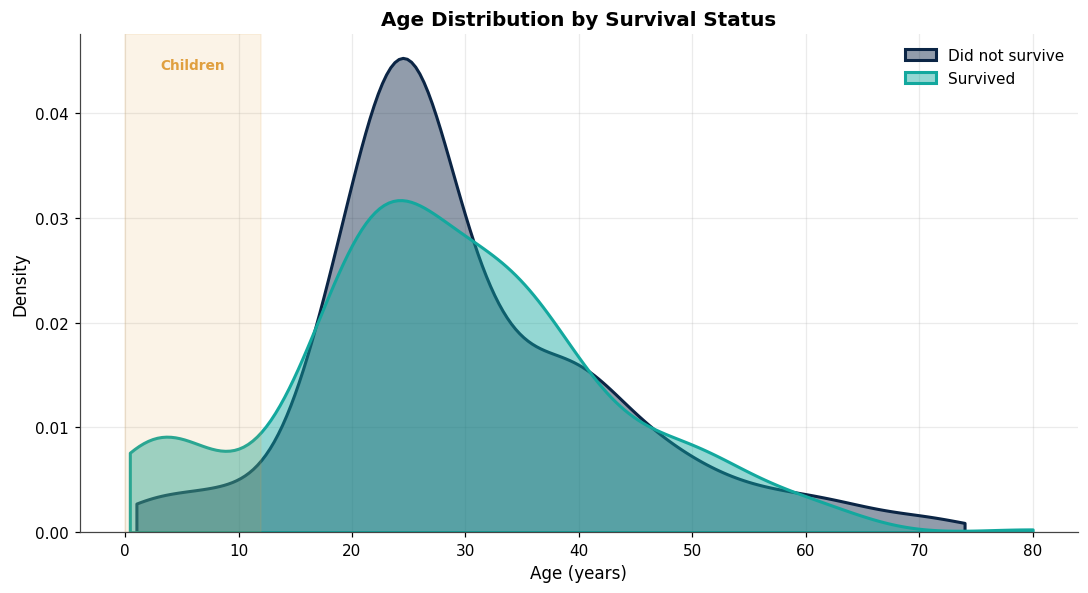

In [65]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.kdeplot(data=df[df.Survived == 0], x="Age", fill=True, color=NAVY, alpha=.45, lw=2, cut=0, label="Did not survive", ax=ax)
sns.kdeplot(data=df[df.Survived == 1], x="Age", fill=True, color=TEAL, alpha=.45, lw=2, cut=0, label="Survived", ax=ax)

ax.axvspan(0, 12, color=AMBER, alpha=.12)
ax.text(6, ax.get_ylim()[1] * .93, "Children", ha="center", fontsize=9, color=AMBER, fontweight="bold")
ax.set_title("Age Distribution by Survival Status")
ax.set_xlabel("Age (years)"); ax.set_ylabel("Density"); ax.legend(frameon=False)
plt.tight_layout()
save_fig("03_age_kde")

<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observations</b><ul style="margin:6px 0 2px 0"><li>The teal (survived) curve has a clear <b>bulge below age 12</b>: young children were disproportionately saved.</li><li>The navy (did not survive) curve peaks in the <b>20&ndash;35</b> range, where most adult men are concentrated.</li><li>Beyond about 60 the curves converge with few passengers, so conclusions there are weak.</li></ul></div>

### 6.4 Supporting visuals: family size and age brackets

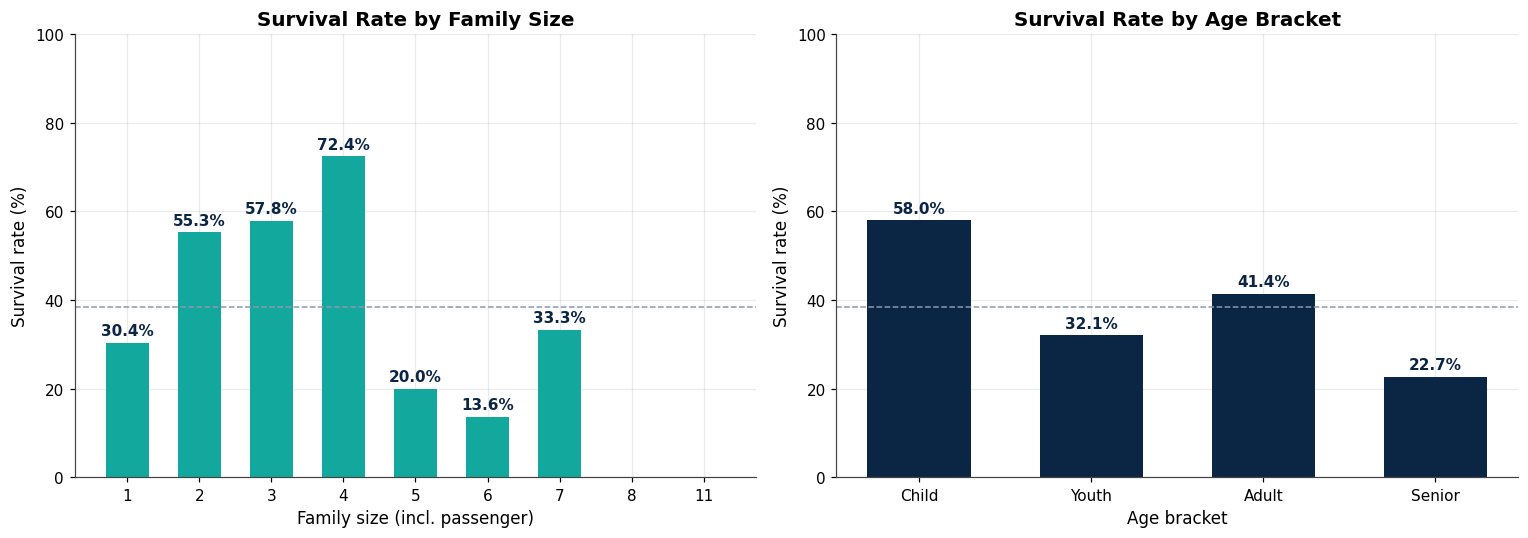

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

f = df.groupby("Family_Size")["Survived"].mean().mul(100)
axes[0].bar(f.index.astype(str), f.values, color=TEAL, width=.6)
axes[0].set_title("Survival Rate by Family Size"); axes[0].set_xlabel("Family size (incl. passenger)")

a = df.groupby("Age_Group", observed=True)["Survived"].mean().mul(100)
axes[1].bar([s.split(" ")[0] for s in a.index.astype(str)], a.values, color=NAVY, width=.6)
axes[1].set_title("Survival Rate by Age Bracket"); axes[1].set_xlabel("Age bracket")

for ax in axes:
    ax.set_ylim(0, 100); ax.set_ylabel("Survival rate (%)"); label_bars(ax)
    ax.axhline(overall * 100, color=GREY, ls="--", lw=1)
plt.tight_layout()
save_fig("04_family_age")

### 6.5 Class &times; age distribution (small multiples)

This view, borrowed from the classic Titanic workflow, shows *who* travelled in each class and how survival split within each.

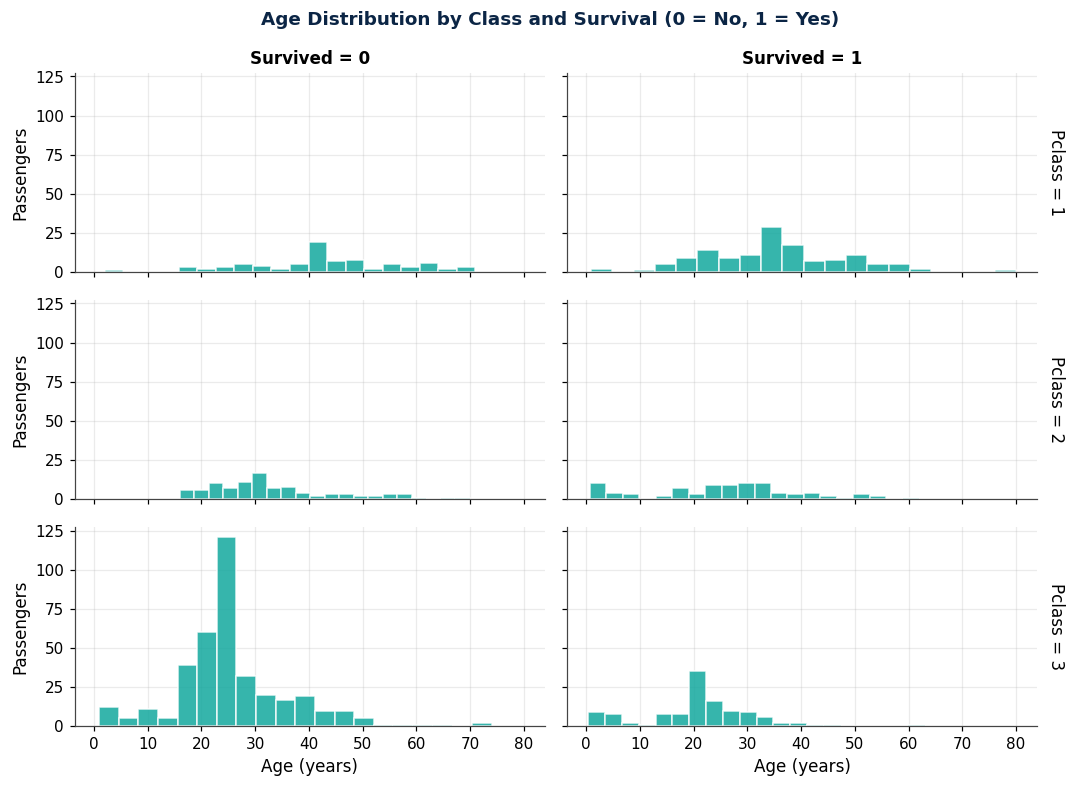

In [67]:
grid = sns.FacetGrid(df, row="Pclass", col="Survived", height=2.3, aspect=2.1, margin_titles=True)
grid.map(plt.hist, "Age", bins=20, color=TEAL, alpha=.85, edgecolor="white")
grid.set_axis_labels("Age (years)", "Passengers")
grid.fig.suptitle("Age Distribution by Class and Survival (0 = No, 1 = Yes)", y=1.03, fontweight="bold", color=NAVY)
save_fig("05_class_age_facets")

<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observations</b><ul style="margin:6px 0 2px 0"><li>Third class (bottom row) carries the largest passenger counts but the <b>smallest survivor bars</b>.</li><li>Young children in 2nd and 3rd class mostly survived, which qualifies the 'children first' pattern across classes.</li><li>Most first-class passengers (top row) survived across almost all ages.</li></ul></div>

<div style="border-left:6px solid #E09F3E;background:#E09F3E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>⚠️ Data-quality caveat visible in this chart</b><ul style="margin:6px 0 2px 0"><li>The tall spike around ages <b>21&ndash;25</b> in 3rd class is partly an <b>imputation artifact</b>: missing ages for 3rd-class passengers were filled with that group's median (25 for men, 21.5 for women).</li><li>This is the trade-off of median imputation. It is acceptable for survival-rate analysis, but the exact age distribution of 3rd class should not be over-interpreted.</li></ul></div>

<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">7. &nbsp;Statistical validation &amp; driver ranking</h2><span style="color:#cfe9e7;font-size:13px">Bonus: are the differences real, and which factor matters most?</span></div>

Descriptive differences can occur by chance. We test each segmentation with a **chi-square test of independence** and report **Cram&eacute;r's V** as the effect size
(0 = no association, 1 = perfect association; roughly 0.1 small, 0.3 medium, 0.5 large).

In [68]:
def cramers_v(ct):
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

rows = []
for col in ["Sex", "Pclass", "Age_Group", "Family_Group", "Embarked", "Cabin_Known"]:
    ct = pd.crosstab(df[col], df["Survived"])
    chi2, p, dof, _ = chi2_contingency(ct)
    rows.append({"Feature": col, "Chi-square": chi2, "p-value": p, "Cramer's V": cramers_v(ct),
                 "Significant (p<0.05)": "Yes" if p < .05 else "No"})

tests = pd.DataFrame(rows).sort_values("Cramer's V", ascending=False).set_index("Feature")
display(tests.style.format({"Chi-square": "{:.1f}", "p-value": "{:.2e}", "Cramer's V": "{:.3f}"})
        .background_gradient(subset=["Cramer's V"], cmap=TEAL_CMAP)
        .set_table_styles([{"selector": "th.col_heading", "props": [("background-color", NAVY), ("color", "white")]}]))

,Chi-square,p-value,Cramer's V,Significant (p<0.05)
Feature,,,,
Sex,260.7,1.20e-58,0.541,Yes
Pclass,102.9,4.55e-23,0.340,Yes
Cabin_Known,87.9,6.74e-21,0.314,Yes
Family_Group,74.5,6.52e-17,0.289,Yes
Embarked,26.0,2.30e-06,0.171,Yes
Age_Group,21.4,8.75e-05,0.155,Yes


<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observations</b><ul style="margin:6px 0 2px 0"><li><b>Every</b> segmentation is statistically significant (p &lt; 0.05); none of the differences is a sampling accident.</li><li><b>Gender</b> has by far the largest effect size (V &asymp; 0.54, a <i>large</i> effect), followed by <b>class</b> (0.34) and <b>cabin record</b> (0.31), both <i>medium</i>. Age bracket and port are small effects (about 0.15 to 0.17).</li></ul></div>

### Driver ranking with a baseline model

As in the classic workflow, **logistic regression coefficients** help confirm which features drive survival. We standardise the inputs so the coefficients are directly comparable.
Positive values raise survival probability; negative values lower it.

5-fold cross-validated accuracy: 80.0%  (baseline if we always predict 'did not survive': 61.6%)


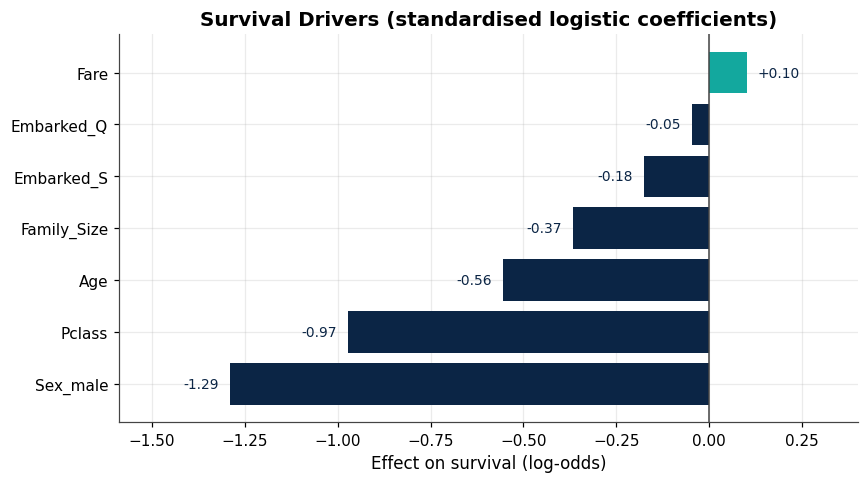

In [69]:
features = df[["Pclass", "Sex", "Age", "Family_Size", "Fare", "Embarked"]].copy()
features["Pclass"] = features["Pclass"].astype(int)
X = pd.get_dummies(features, drop_first=True).astype(float)
X = (X - X.mean()) / X.std()
y = df["Survived"]

logreg = LogisticRegression(max_iter=1000)
cv_acc = cross_val_score(logreg, X, y, cv=5).mean()
logreg.fit(X, y)

coef = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
print(f"5-fold cross-validated accuracy: {cv_acc:.1%}  (baseline if we always predict 'did not survive': {1 - y.mean():.1%})")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(coef.index, coef.values, color=[TEAL if v > 0 else NAVY for v in coef.values])
for i, v in enumerate(coef.values):
    ax.text(v + (.03 if v > 0 else -.03), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=9, color=NAVY)
ax.axvline(0, color="#444", lw=1)
ax.set_title("Survival Drivers (standardised logistic coefficients)"); ax.set_xlabel("Effect on survival (log-odds)")
ax.set_xlim(coef.min() - .3, coef.max() + .3)
plt.tight_layout()
save_fig("06_driver_ranking")

<div style="border-left:6px solid #13A89E;background:#13A89E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>🔎 Observations</b><ul style="margin:6px 0 2px 0"><li>Being <b>male</b> is the strongest negative driver, followed by a <b>lower class</b>, then <b>higher age</b> and <b>larger family size</b>: the same ranking the descriptive tables gave us.</li><li><b>Fare</b> adds almost nothing once class is known, since the two carry overlapping information.</li><li>Cross-validated accuracy of about <b>80%</b> (vs 61.6% for the naive baseline) shows these simple features capture most of the signal.</li></ul></div>

<div style="background:#0B2545;padding:12px 20px;border-radius:8px;border-bottom:4px solid #13A89E"><h2 style="margin:0;color:#fff">8. &nbsp;Executive summary</h2><span style="color:#cfe9e7;font-size:13px">One-page briefing for business stakeholders</span></div>

In [70]:
best = survival_table(["Sex", "Pclass"]).sort_values("Survival %", ascending=False)
kpi_cards([
    ("Overall survival", f"{overall:.1%}", f"{int(df.Survived.sum())} of {len(df)} passengers"),
    ("Women vs men", f"{df[df.Sex=='female'].Survived.mean():.0%} vs {df[df.Sex=='male'].Survived.mean():.0%}", "gender gap"),
    ("1st vs 3rd class", f"{df[df.Pclass==1].Survived.mean():.0%} vs {df[df.Pclass==3].Survived.mean():.0%}", "class gap"),
    ("Best segment", f"{best['Survival %'].iloc[0]:.1f}%", f"{best.index[0][0]} / class {best.index[0][1]}"),
    ("Worst segment", f"{best['Survival %'].iloc[-1]:.1f}%", f"{best.index[-1][0]} / class {best.index[-1][1]}"),
])

### Bottom line

> **Survival was determined mainly by *who you were*.** Gender came first, ticket class second, and age and family context third.
> Outcomes ranged from **96.8%** (first-class women) to **13.5%** (third-class men), an **83-point spread** inside a single ship.

### Key drivers of survival

| Rank | Driver | Evidence |
|:-:|:--|:--|
| 1 | **Gender** | Women 74.2% vs men 18.9%; strongest correlation (0.54) and largest effect size |
| 2 | **Ticket class** | 1st 63.0% &rarr; 2nd 47.3% &rarr; 3rd 24.2% |
| 3 | **Age** | Children (0-12) 58.0%; seniors 22.7% (small sample) |
| 4 | **Family structure** | Small groups of 2-4 at 57.9%; solo 30.4%; large families (5+) 16.1% |

<div style="border-left:6px solid #1F6F8B;background:#1F6F8B1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>💡 Key insight</b><ul style="margin:6px 0 2px 0"><li>Gender and class <b>compound</b> each other. Class protected women far more than men, and a 3rd-class woman had better odds than a 1st-class man.</li></ul></div>

### Data quality notes

<div style="border-left:6px solid #E09F3E;background:#E09F3E1F;padding:10px 18px;border-radius:6px;margin:8px 0"><b>⚠️ Read before presenting</b><ul style="margin:6px 0 2px 0"><li><b>Age</b> (19.9% missing) was imputed by Pclass &times; Sex median. The gaps were <b>not random</b> (27.7% in 3rd class), so age-based findings carry extra uncertainty.</li><li><b>Cabin</b> (77.1% missing) was <b>not</b> imputed; it is used only as a known/unknown indicator and reflects record-keeping, not cabin location.</li><li><b>Embarked</b>: 2 values filled with the mode. Immaterial.</li><li><b>Small samples:</b> only 22 seniors and 62 passengers in large families, so quote those rates as indicative.</li><li><b>Scope:</b> 891 of about 2,224 people aboard. Findings are <b>associations</b>, not proof of causation.</li></ul></div>

### Actionable insights

1. **Protect by vulnerability, not rank.** The least-protected groups (3rd-class men at 13.5% and large families at 16.1%) were those with the fewest resources. Safety and evacuation design should target them explicitly.
2. **Plan for groups.** Solo travellers *and* large families both did poorly; procedures must account for people without a group or burdened by one.
3. **Track inequity as a KPI.** An 83-point outcome gap across segments is a measurable metric an organisation can monitor and aim to reduce.
4. **Analytics practice.** Segment-level views (gender &times; class) revealed what single-variable views hid, and non-linear effects such as family size need binned features, not raw correlation.
5. **Next step for modelling:** use `Title`, `Deck`, and fare-per-person, then try gradient boosting. The ~80% logistic baseline is the benchmark to beat.

### Presentation tips
- **Hero slide:** chart 5.1 (three-panel bars). **Story slide:** the 'women and children first' view from chart 5.3 and the 58% child survival rate.
- All charts are saved at 300 DPI in the `figures/` folder (see the Colab file panel on the left).

In [71]:
# List the presentation-ready charts created by this notebook
for f in sorted(os.listdir("figures")):
    print("🖼️ ", f"figures/{f}")

🖼️  figures/01_survival_bars.png
🖼️  figures/02_correlation_heatmap.png
🖼️  figures/03_age_kde.png
🖼️  figures/04_family_age.png
🖼️  figures/05_class_age_facets.png
🖼️  figures/06_driver_ranking.png


## References

This notebook follows the step-by-step workflow style of *Data Science Solutions* and the Kaggle Titanic competition.

- [Kaggle Titanic data page](https://www.kaggle.com/c/titanic/data)
- [Data Science Solutions, Startup Workflow](https://www.amazon.com/Data-Science-Solutions-Startup-Workflow/dp/1520545312)
- [A journey through Titanic](https://www.kaggle.com/omarelgabry/titanic/a-journey-through-titanic)